# P6 - Neural Network Classification, Model Selection, Model Evaluation

## Neural Network Classification using the Iris Dataset

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

# We will use an example dataset that comes with scikit learn
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
print(iris.data.shape)
print(iris.target.shape)

(150, 4)
(150,)


In [2]:
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [3]:
df = iris.frame
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [5]:
X = iris.data
y = iris.target

In [6]:
X

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


Let's check how many unique values we have in the target column (i.e., how many classes we have)

In [9]:
y.unique()

array([0, 1, 2])

Let's split the data into train and test set first!
We choose the test set to be 20% of the data.

In [10]:
from sklearn.model_selection import train_test_split

X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=1337)

# Model Selection
## The Holdout Method

Split off a validation set. Again, we slice out 20% of the remaining training data for validation.

In [11]:
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=1337)

In [12]:
from sklearn.neural_network import MLPClassifier

nn = MLPClassifier(max_iter=1000,
                   hidden_layer_sizes=(32,), 
                   solver='adam',
                   random_state=1337, verbose=False)

nn.fit(X_train, y_train)
print(f'Final Train Loss: {nn.loss_}')

Final Train Loss: 0.08683211921445572


In [13]:
y_pred_val = nn.predict(X_val)
print(y_pred_val)

[0 0 1 2 1 2 1 2 1 1 0 1 1 2 0 0 2 0 0 0 2 2 0 1]


In [14]:
print(np.array(y_val))

[0 0 1 2 1 2 1 2 1 1 0 1 1 2 0 0 2 0 0 0 2 1 0 1]


In [17]:
from sklearn.metrics import classification_report

# show classification report
print(classification_report(y_val, y_pred_val))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         9
           1       1.00      0.89      0.94         9
           2       0.86      1.00      0.92         6

    accuracy                           0.96        24
   macro avg       0.95      0.96      0.95        24
weighted avg       0.96      0.96      0.96        24



In [18]:
nn = MLPClassifier(max_iter=1000,
                   hidden_layer_sizes=(200,100), 
                   solver='adam',
                   random_state=1337, verbose=False)

nn.fit(X_train, y_train)
print(f'Final Train Loss: {nn.loss_}')

Final Train Loss: 0.06096213600946505


In [19]:
y_pred_val = nn.predict(X_val)
print(classification_report(y_val, y_pred_val))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         9
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00         6

    accuracy                           1.00        24
   macro avg       1.00      1.00      1.00        24
weighted avg       1.00      1.00      1.00        24



## Grid Search with Cross Validation

The validation set we have used is pretty small. We can use cross validation to get a better estimate of the model's performance.
Also, we can try out a few different hyperparameters using Grid Search.

In [20]:
from sklearn.model_selection import GridSearchCV

params = {
            'hidden_layer_sizes' : [(200,), (400,)],
            'solver' : ['adam', 'lbfgs']
         }

nn = MLPClassifier(max_iter=500, random_state=1337)
gs = GridSearchCV(nn, params, cv=5, verbose=4)
gs.fit(X_train_full, y_train_full) # Note: We use the full training set here (without splitting off a validation set)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV 1/5] END hidden_layer_sizes=(200,), solver=adam;, score=0.958 total time=   0.1s
[CV 2/5] END hidden_layer_sizes=(200,), solver=adam;, score=0.958 total time=   0.1s
[CV 3/5] END hidden_layer_sizes=(200,), solver=adam;, score=0.958 total time=   0.1s
[CV 4/5] END hidden_layer_sizes=(200,), solver=adam;, score=1.000 total time=   0.1s
[CV 5/5] END hidden_layer_sizes=(200,), solver=adam;, score=1.000 total time=   0.1s
[CV 1/5] END hidden_layer_sizes=(200,), solver=lbfgs;, score=0.958 total time=   0.0s
[CV 2/5] END hidden_layer_sizes=(200,), solver=lbfgs;, score=0.958 total time=   0.0s
[CV 3/5] END hidden_layer_sizes=(200,), solver=lbfgs;, score=0.917 total time=   0.1s
[CV 4/5] END hidden_layer_sizes=(200,), solver=lbfgs;, score=1.000 total time=   0.0s
[CV 5/5] END hidden_layer_sizes=(200,), solver=lbfgs;, score=0.958 total time=   0.0s
[CV 1/5] END hidden_layer_sizes=(400,), solver=adam;, score=0.958 total time=   0.1s


GridSearchCV(cv=5, estimator=MLPClassifier(max_iter=500, random_state=1337),
             param_grid={'hidden_layer_sizes': [(200,), (400,)],
                         'solver': ['adam', 'lbfgs']},
             verbose=4)

In [21]:
print(gs.best_params_)
print(gs.best_score_) # best mean cross-validated score (accuracy)

{'hidden_layer_sizes': (200,), 'solver': 'adam'}
0.975


In [22]:
nn = gs.best_estimator_

Let's show the confusion matrix on the test set

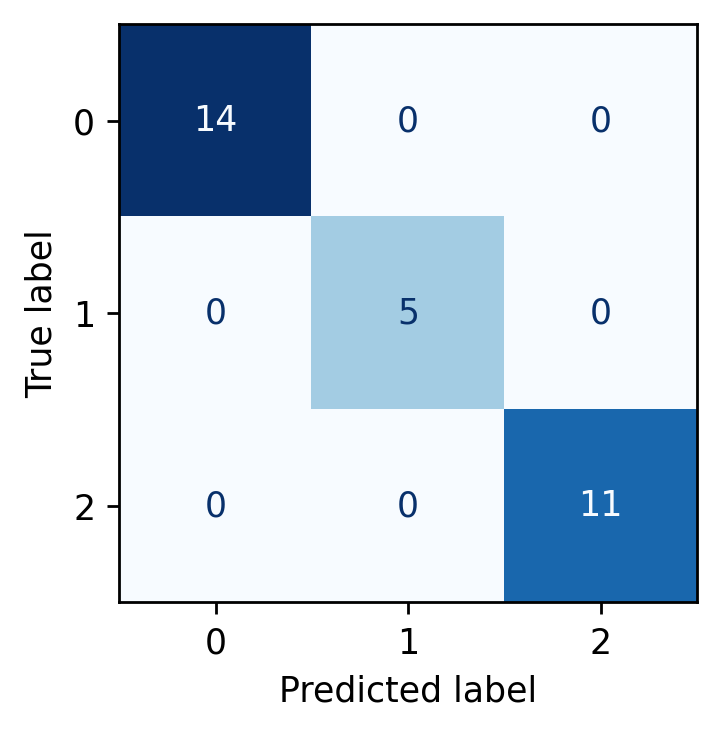

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = nn.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nn.classes_)
fig, ax = plt.subplots(figsize=(3, 3), dpi=250)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.show()